# Práctica de laboratorio: Análisis y visualización de calificaciones con Pandas y Matplotlib

**Asignatura:** Tópicos Avanzados de Programación  
**Nombre:** Gabriel Hernandez Gallegos
**Número de control:** 26070002

Este notebook muestra el funcionamiento de cada uno de los seis ejercicios de `practica_pandas.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

## Ejercicio 1. Carga y revisión

Se lee el archivo `calificaciones_isc.csv` en un DataFrame llamado `df` y se revisa su contenido.

In [2]:
df = pd.read_csv("calificaciones_isc.csv")

print("Primeras 5 filas:")
df.head()

Primeras 5 filas:


,matricula,nombre,grupo,materia,unidad,calificacion,asistencias
0,ISC240100,Ana Lopez,A,Programacion,1,55,5
1,ISC240100,Ana Lopez,A,Programacion,2,54,5
2,ISC240100,Ana Lopez,A,Programacion,3,50,8
3,ISC240100,Ana Lopez,A,Bases de datos,1,58,7
4,ISC240100,Ana Lopez,A,Bases de datos,2,49,8


In [3]:
print("Filas y columnas:", df.shape)
print(f"Número de filas: {df.shape[0]}  |  Número de columnas: {df.shape[1]}")

Filas y columnas: (288, 7)
Número de filas: 288  |  Número de columnas: 7


In [4]:
print("Tipo de dato de cada columna:")
df.dtypes

Tipo de dato de cada columna:


matricula         str
nombre            str
grupo             str
materia           str
unidad          int64
calificacion    int64
asistencias     int64
dtype: object

In [5]:
print("Resumen estadístico de calificacion y asistencias:")
df[["calificacion", "asistencias"]].describe()

Resumen estadístico de calificacion y asistencias:


,calificacion,asistencias
count,288.000000,288.000000
mean,69.454861,6.635417
std,12.249072,1.723701
min,35.000000,4.000000
25%,60.750000,5.000000
50%,69.000000,7.000000
75%,78.000000,8.000000
max,100.000000,9.000000


**¿Por qué 288 registros y no 24?**  
Cada alumno aparece en varias filas: una por cada materia y por cada unidad. Son 24 alumnos × 4 materias × 3 unidades = 288 filas.

## Ejercicio 2. Filtros

Se filtra sin modificar `df` y se cuenta con `len()`, sin ciclos.

In [6]:
solo_grupo_a = df[df["grupo"] == "A"]
menores_70 = df[df["calificacion"] < 70]
bd_grupo_b_80 = df[
    (df["materia"] == "Bases de datos")
    & (df["grupo"] == "B")
    & (df["calificacion"] >= 80)
]

print("Filas del grupo A:", len(solo_grupo_a))
print("Filas con calificación menor a 70:", len(menores_70))
print("Filas de Bases de datos, grupo B, calificación >= 80:", len(bd_grupo_b_80))

Filas del grupo A: 144
Filas con calificación menor a 70: 146
Filas de Bases de datos, grupo B, calificación >= 80: 15


In [7]:
bd_grupo_b_80.head()

,matricula,nombre,grupo,materia,unidad,calificacion,asistencias
147,ISC240112,Paola Cruz,B,Bases de datos,1,85,5
148,ISC240112,Paola Cruz,B,Bases de datos,2,81,8
149,ISC240112,Paola Cruz,B,Bases de datos,3,81,6
159,ISC240113,Andres Reyes,B,Bases de datos,1,80,9
171,ISC240114,Camila Ortiz,B,Bases de datos,1,80,4


## Ejercicio 3. Columna calculada

Se crea la columna `situacion` con `np.where`: "Aprobado" si la calificación es mayor o igual a 70, y "Reprobado" en otro caso.

In [8]:
df["situacion"] = np.where(df["calificacion"] >= 70, "Aprobado", "Reprobado")
df[["matricula", "materia", "unidad", "calificacion", "situacion"]].head(10)

,matricula,materia,unidad,calificacion,situacion
0,ISC240100,Programacion,1,55,Reprobado
1,ISC240100,Programacion,2,54,Reprobado
2,ISC240100,Programacion,3,50,Reprobado
3,ISC240100,Bases de datos,1,58,Reprobado
4,ISC240100,Bases de datos,2,49,Reprobado
5,ISC240100,Bases de datos,3,55,Reprobado
6,ISC240100,Redes,1,40,Reprobado
7,ISC240100,Redes,2,44,Reprobado
8,ISC240100,Redes,3,49,Reprobado
9,ISC240100,Matematicas discretas,1,42,Reprobado


## Ejercicio 4. Resúmenes

### a) Promedio de calificación por materia

In [9]:
prom_materia = df.groupby("materia")["calificacion"].mean()
prom_materia.round(2)

materia
Bases de datos           74.43
Matematicas discretas    62.56
Programacion             71.65
Redes                    69.18
Name: calificacion, dtype: float64

### b) Promedio por grupo y materia

In [10]:
prom_grupo_materia = df.groupby(["grupo", "materia"])["calificacion"].mean()
prom_grupo_materia.round(2)

grupo  materia              
A      Bases de datos           75.39
       Matematicas discretas    64.33
       Programacion             71.42
       Redes                    68.47
B      Bases de datos           73.47
       Matematicas discretas    60.78
       Programacion             71.89
       Redes                    69.89
Name: calificacion, dtype: float64

### c) Promedio general de cada alumno (de mayor a menor)

Se agrupa por `matricula` y `nombre` para conservar ambos datos, y se usa `reset_index()` para que dejen de ser índice.

In [11]:
prom_alumno = (
    df.groupby(["matricula", "nombre"])["calificacion"]
    .mean()
    .sort_values(ascending=False)
    .reset_index(name="promedio")
)
prom_alumno.round(2)

,matricula,nombre,promedio
0,ISC240111,Ricardo Morales,89.00
1,ISC240108,Valeria Torres,85.17
2,ISC240112,Paola Cruz,80.75
3,ISC240106,Daniela Perez,77.00
4,ISC240118,Natalia Ramos,76.25
5,ISC240110,Fernanda Rivera,75.75
6,ISC240101,Carlos Ramirez,75.50
7,ISC240121,Oscar Medina,75.08
8,ISC240120,Lucia Navarro,74.17
9,ISC240122,Karla Aguilar,73.75


### d) Promedio general por unidad (todas las materias juntas)

In [12]:
prom_unidad = df.groupby("unidad")["calificacion"].mean()
prom_unidad.round(2)

unidad
1    68.52
2    69.34
3    70.50
Name: calificacion, dtype: float64

### e) Unidades aprobadas y reprobadas

In [13]:
conteo_situacion = df["situacion"].value_counts()
conteo_situacion

situacion
Reprobado    146
Aprobado     142
Name: count, dtype: int64

### Exportar el promedio por alumno

Con `index=False` para no guardar el índice de Pandas. La matrícula y el nombre se conservan porque se aplicó `reset_index()`.

In [14]:
prom_alumno.to_csv("promedios_alumnos.csv", index=False)

# Verificación: se lee el archivo exportado
pd.read_csv("promedios_alumnos.csv").head()

,matricula,nombre,promedio
0,ISC240111,Ricardo Morales,89.000000
1,ISC240108,Valeria Torres,85.166667
2,ISC240112,Paola Cruz,80.750000
3,ISC240106,Daniela Perez,77.000000
4,ISC240118,Natalia Ramos,76.250000


## Ejercicio 5. Gráficas

Cada figura tiene título y ejes con nombre, y se guarda como PNG **antes** de mostrarse.

### Gráfica 1: promedio por materia (barras)

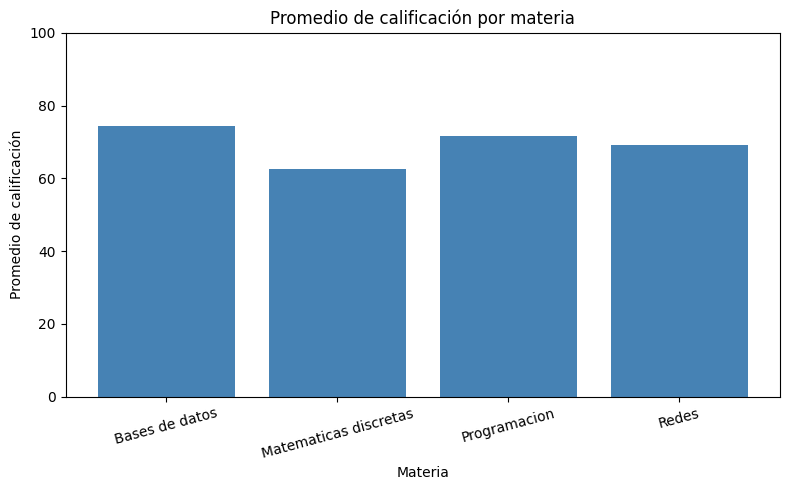

In [15]:
plt.figure(figsize=(8, 5))
plt.bar(prom_materia.index, prom_materia.values, color="steelblue")
plt.title("Promedio de calificación por materia")
plt.xlabel("Materia")
plt.ylabel("Promedio de calificación")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("promedio_materias.png", dpi=150)
plt.show()

### Gráfica 2: histograma de todas las calificaciones

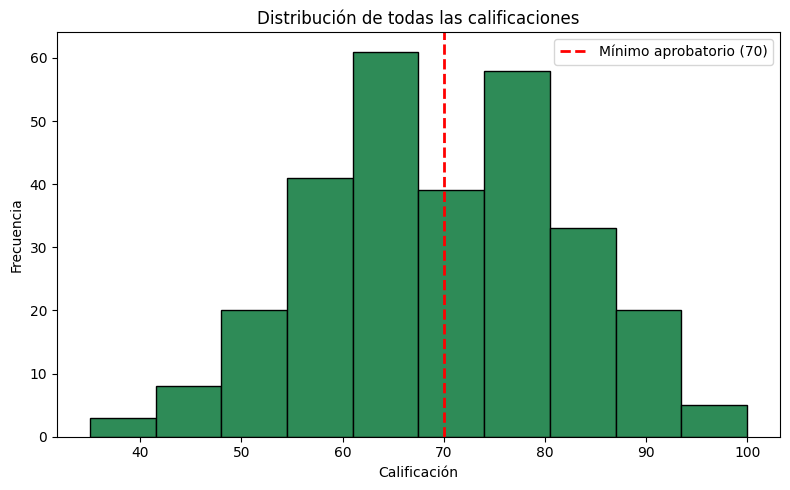

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df["calificacion"], bins=10, color="seagreen", edgecolor="black")
plt.axvline(70, color="red", linestyle="--", linewidth=2, label="Mínimo aprobatorio (70)")
plt.title("Distribución de todas las calificaciones")
plt.xlabel("Calificación")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.savefig("histograma.png", dpi=150)
plt.show()

### Gráfica 3: tendencia del promedio por unidad (una línea por materia)

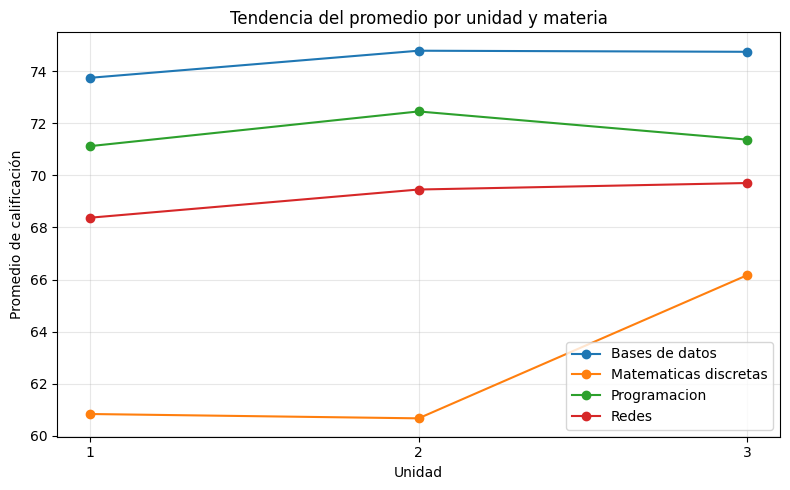

In [17]:
tendencia = df.groupby(["unidad", "materia"])["calificacion"].mean().unstack()

plt.figure(figsize=(8, 5))
for materia in tendencia.columns:
    plt.plot(tendencia.index, tendencia[materia], marker="o", label=materia)
plt.title("Tendencia del promedio por unidad y materia")
plt.xlabel("Unidad")
plt.ylabel("Promedio de calificación")
plt.xticks([1, 2, 3])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("tendencia_unidades.png", dpi=150)
plt.show()

## Ejercicio 6. Lectura de resultados

Las respuestas salen de los resúmenes del ejercicio 4 y de las gráficas.

In [18]:
materia_baja = prom_materia.idxmin()
print(f"Materia con el promedio más bajo: {materia_baja} ({prom_materia.min():.2f})")

u1, u2, u3 = prom_unidad.loc[1], prom_unidad.loc[2], prom_unidad.loc[3]
print(f"Promedios por unidad -> U1: {u1:.2f}, U2: {u2:.2f}, U3: {u3:.2f}")
print("¿La unidad 3 es menor que las unidades 1 y 2?", "Sí" if u3 < min(u1, u2) else "No")

alumnos_bajo_70 = (prom_alumno["promedio"] < 70).sum()
print(f"Alumnos con promedio general menor a 70: {alumnos_bajo_70}")

Materia con el promedio más bajo: Matematicas discretas (62.56)
Promedios por unidad -> U1: 68.52, U2: 69.34, U3: 70.50
¿La unidad 3 es menor que las unidades 1 y 2? No
Alumnos con promedio general menor a 70: 11


### Interpretación

- **Materia con el promedio más bajo:** Matematicas discretas, con un promedio de 62.56.
- **Unidad 3 frente a unidades 1 y 2:** el promedio de la unidad 3 (70.50) **no** es menor que el de la unidad 1 (68.52) ni el de la unidad 2 (69.34); el grupo sube ligeramente hacia la unidad 3.
- **Alumnos bajo 70 en su promedio general:** 11 de 24.

*(Estos números corresponden al archivo `calificaciones_isc.csv` incluido. Si cambias el CSV, actualiza esta interpretación con los nuevos resultados.)*